# Understanding the STFT representation

How does overlap change the time-frequency representation of the same signal window? Both exploratory profiles use 4096 samples and a 512-sample Hann window. A overlaps by 256 samples, while B overlaps by 448, producing more time frames without changing the FFT frequency spacing.

The default path inspects the preserved split and plots a clearly labeled synthetic illustration. It needs no raw data and creates no image dataset. Optional generation requires the ten load-0 recordings through `CWRU_DATA_ROOT`; outputs go to new directories beneath `CWRU_ARTIFACT_ROOT`. Read the rate limitation below before interpreting physical frequencies.


In [1]:
from pathlib import Path
import os, sys
candidates = [Path.cwd(), *Path.cwd().parents]
REPO = next((p for p in candidates if (p / 'src/cwru_bearing').is_dir()), None)
if REPO is None:
    raise RuntimeError('Open this notebook from the repository checkout or its notebooks directory.')
sys.path.insert(0, str(REPO / 'src'))
from cwru_bearing.data import load_config, load_manifest
DATA_ROOT = Path(os.environ['CWRU_DATA_ROOT']) if os.environ.get('CWRU_DATA_ROOT') else None
ARTIFACT_ROOT = Path(os.environ.get('CWRU_ARTIFACT_ROOT', str(REPO / 'runs')))
print('Data configured:', DATA_ROOT is not None)
print('No training is enabled by default.')

In [2]:
config_a, config_b = load_config('stft_a'), load_config('stft_b')
manifest = load_manifest(config_a)
print(manifest.groupby(['split','class_label']).size().unstack(fill_value=0))

class_label   0   1   2   3   4   5   6   7   8   9
split                                              
gap           2   2   2   2   2   2   2   2   2   2
test          3   3   3   3   3   3   3   3   3   3
train        20  20  20  20  20  20  20  20  20  20
val           4   4   4   4   4   4   4   4   4   4


## A numerical illustration

The sine wave below is synthetic. It illustrates array dimensions and the representation, not observed bearing behavior. Both panels use the historical 12 kHz processing label. Changing that label alone leaves the retained magnitudes unchanged, while changing the physical interpretation of the axes.


A shape: (257, 15) B shape: (257, 57)
Same magnitudes after rate-label change: True


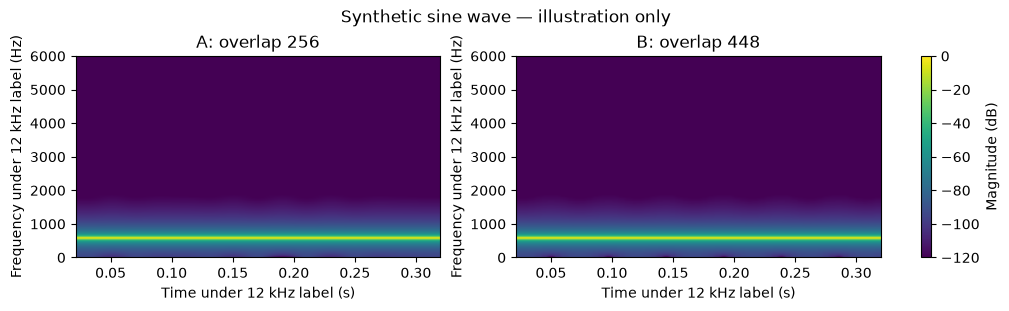

In [3]:
import numpy as np
from cwru_bearing.preprocessing import spectrogram_db
x = np.sin(np.arange(4096) * 0.3)
a, b = spectrogram_db(x, config_a), spectrogram_db(x, config_b)
print('A shape:', a.shape, 'B shape:', b.shape)
print('Same magnitudes after rate-label change:', np.array_equal(b, spectrogram_db(x, {**config_b, 'processing_rate_hz':48000})))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for ax, values, name in zip(axes, [a, b], ['A: overlap 256', 'B: overlap 448']):
    shown = ax.imshow(values, origin='lower', aspect='auto',
                      extent=[256/12000, 3840/12000, 0, 6000], vmin=-120, vmax=0)
    ax.set(title=name, xlabel='Time under 12 kHz label (s)', ylabel='Frequency under 12 kHz label (Hz)')
fig.colorbar(shown, ax=axes, label='Magnitude (dB)')
fig.suptitle('Synthetic sine wave — illustration only')
plt.show()


## Scaling and saved evidence

Each profile fits its own .5/99.5 percentile limits using training spectra alone, retains float64 source signals, truncates scaled values to uint8, and flips the frequency direction for PNG storage. Original exploration cells E150/E154 define this behavior; E means the exploratory notebook and D means the training notebook, using one-based cell numbers.

Both A and B reached selected validation macro-F1 of 1 in saved cells D23/D25. No A/B test score was preserved. Because recordings recur across splits and the original session consumed an extra sanity batch for A, these observations do not establish B's superiority. Independent CLI runs preserve settings but cannot reconstruct the entire original shared-session RNG progression.


In [4]:
import re
import pandas as pd
from IPython.display import display
summaries = []
for profile, cell in [('A', 23), ('B', 25)]:
    text = (REPO / f'results/historical/D_cell_{cell:03d}.txt').read_text(encoding='utf-8')
    selected = re.search(r'Best [AB]: epoch=(\d+), Val Macro-F1=([\d.]+), Val loss=([\d.]+)', text)
    if selected is None:
        raise ValueError(f'Missing saved selection summary for profile {profile}')
    epoch, f1, loss = selected.groups()
    summaries.append({'Profile': profile, 'Selected epoch': int(epoch),
                      'Validation macro-F1': float(f1), 'Validation loss': float(loss)})
display(pd.DataFrame(summaries).set_index('Profile'))


,Selected epoch,Validation macro-F1,Validation loss
Profile,,,
A,14,1.0,0.4099
B,15,1.0,0.2815


## Optional preprocessing

Requires the ten load-0 recordings. Outputs go to a new ignored artifact directory. This preserves the acquisition mismatch; it does not harmonize rates.

In [5]:
RUN_PREPROCESS = False
if RUN_PREPROCESS:
    if DATA_ROOT is None:
        raise RuntimeError('Configure CWRU_DATA_ROOT first.')
    from cwru_bearing.data import validate_recordings
    from cwru_bearing.preprocessing import generate
    for config in [config_a, config_b]:
        validate_recordings(DATA_ROOT, config)
        print(generate(DATA_ROOT, ARTIFACT_ROOT / 'images' / config['name'], config))
else:
    print('Preprocessing disabled.')

Training A/B is available through the explicit CLI commands in the [execution guide](../docs/reproduction.md), with 15 classifier-only epochs per profile. New full training has not independently reproduced the saved findings. A/B test evaluation is a new result and must not be added to the historical result table.

[Project overview](../README.md) | [Previous notebook](02_classical_baselines.ipynb) | [Next notebook](04_cross_load.ipynb)
